# Analyse des doublons

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 2 - Préparer le jeu de données  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Le notebook `01.01` a repéré des fichiers binaires identiques. Ce notebook caractérise ces doublons et valide la règle de déduplication implémentée dans `brain_mri.dataset`. Il répond aux questions suivantes :

- Où se situent les doublons : parmi les images non annotées, annotées, ou entre les deux ?
- Existe-t-il des labels contradictoires au sein d'un groupe de doublons ?
- Quelle copie conserver, et que devient le sous-ensemble annoté ?
- Existe-t-il des quasi-doublons que le hash binaire ne détecte pas ?

Les données restent **immutables** dans `data/raw/` : ce notebook ne supprime aucun fichier : il applique en mémoire les fonctions de `brain_mri.dataset` pour en vérifier l'effet.

## 1. Chargement

L'inventaire et les empreintes SHA-256 proviennent de `brain_mri.dataset`.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from brain_mri.config import FIGURES_DIR, INTERIM_DATA_DIR, RAW_DATA_DIR
from brain_mri.dataset import (
    EXCLUDED_IMAGES,
    NEAR_DUPLICATE_THRESHOLD,
    ORIENTATIONS,
    NearDuplicateSearch,
    add_file_hash,
    build_inventory,
    deduplicate,
    deduplicate_exact,
    deduplicate_near,
    find_near_duplicate_pairs,
    nearest_neighbors,
    read_manifest,
)

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

inventory = add_file_hash(build_inventory(RAW_DATA_DIR))
print(
    f"{len(inventory):,} images, dont {inventory['is_labeled'].sum():,} annotées."
)

1,506 images, dont 100 annotées.


## 2. Images illisibles

Une image qui ne s'ouvre pas ou ne se décode pas entièrement fausserait l'extraction des features. On tente de décoder chacune des images brutes.

In [2]:
def is_readable(filepath):
    """Indique si l'image s'ouvre et se décode entièrement."""
    try:
        with Image.open(filepath) as image:
            image.load()
    except (OSError, ValueError):
        return False
    return True


readable = inventory["filepath"].map(is_readable)
print(f"{(~readable).sum()} image(s) illisible(s) sur {len(inventory):,}.")
display(inventory.loc[~readable, ["image_id", "subset"]])

0 image(s) illisible(s) sur 1,506.


,image_id,subset


## 3. Image exclue à la main

Une image est **inexploitable à l'œil** : une tache blanche saturée, sans aucun détail anatomique. Elle décode sans erreur, mais ses caractéristiques ne seraient que du bruit pour le modèle. Elle est listée dans `EXCLUDED_IMAGES` avec sa raison. Le fichier brut n'est jamais modifié : l'image est seulement retirée du manifeste, **avant** toute déduplication, pour qu'elle ne soit jamais conservée comme copie d'une autre.

Elle n'est pas annotée : le jeu annoté reste complet. Les autres images atypiques (couleurs, valeurs extrêmes) sont de vraies IRM lisibles et restent.

1 image(s) exclue(s) à la main, dont 0 annotée(s).


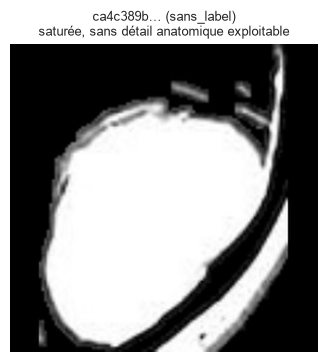

1,505 images conservées pour la suite.


In [3]:
excluded_rows = inventory[inventory["image_id"].isin(EXCLUDED_IMAGES)]
assert len(excluded_rows) == len(EXCLUDED_IMAGES), (
    "Une image exclue est absente de l'inventaire."
)
print(
    f"{len(excluded_rows)} image(s) exclue(s) à la main, dont "
    f"{int(excluded_rows['is_labeled'].sum())} annotée(s)."
)

figure, axes = plt.subplots(
    1, len(excluded_rows), figsize=(4 * len(excluded_rows), 4), squeeze=False
)
for axis, (_, row) in zip(axes[0], excluded_rows.iterrows(), strict=True):
    with Image.open(row["filepath"]) as image:
        axis.imshow(image.convert("L"), cmap="gray", vmin=0, vmax=255)
    axis.set_title(
        f"{row['image_id'][:8]}… ({row['subset']})\n{EXCLUDED_IMAGES[row['image_id']]}",
        fontsize=9,
    )
    axis.axis("off")
figure.savefig(FIGURES_DIR / "image-exclue.png", dpi=110, bbox_inches="tight")
plt.show()

# Dès maintenant, `images` ne contient plus les images exclues : toutes les
# analyses qui suivent partent de ce jeu.
images = inventory[~inventory["image_id"].isin(EXCLUDED_IMAGES)].reset_index(
    drop=True
)
print(f"{len(images):,} images conservées pour la suite.")

## 4. Doublons exacts

Un groupe rassemble tous les fichiers de même empreinte SHA-256. Pour chaque groupe, on compte les copies par origine (`cancer`, `normal`, `sans_label`).

In [4]:
duplicated = images.loc[images.duplicated("sha256", keep=False)]

groups = duplicated.groupby("sha256").agg(
    taille=("image_id", "size"),
    n_cancer=("label", lambda labels: (labels == "cancer").sum()),
    n_normal=("label", lambda labels: (labels == "normal").sum()),
    n_sans_label=("is_labeled", lambda flags: (~flags).sum()),
)

composition = (
    groups.groupby(["taille", "n_cancer", "n_normal", "n_sans_label"])
    .size()
    .rename("nombre_groupes")
    .reset_index()
)
display(composition)

n_excess = len(duplicated) - len(groups)
print(
    f"{len(groups)} groupes, {len(duplicated)} fichiers impliqués, {n_excess} copies en trop."
)

,taille,n_cancer,n_normal,n_sans_label,nombre_groupes
0,2,0,0,2,55
1,2,0,1,1,21
2,2,1,0,1,8
3,3,0,0,3,4
4,3,0,1,2,1
5,3,0,2,1,1


90 groupes, 186 fichiers impliqués, 96 copies en trop.


### Cohérence des labels

Un même contenu ne doit jamais porter deux labels différents (`cancer` et `normal`). Dans le cas contraire, il faudrait le retirer du jeu annoté.

In [5]:
labels_per_group = duplicated.groupby("sha256")["label"].nunique()
assert (labels_per_group <= 1).all(), (
    "Des groupes ont des labels contradictoires."
)

groups_with_label = groups[(groups["n_cancer"] + groups["n_normal"]) > 0]
print("Aucun groupe n'a de labels contradictoires.")
print(
    f"Groupes contenant au moins une image annotée : {len(groups_with_label)}"
)

Aucun groupe n'a de labels contradictoires.
Groupes contenant au moins une image annotée : 31


### Doublons au sein du jeu annoté

Une même image annotée en double réduit mécaniquement la taille du jeu d'évaluation.

In [6]:
labeled = images.loc[images["is_labeled"]]
labeled_duplicates = labeled.loc[
    labeled.duplicated("sha256", keep=False),
    ["image_id", "subset", "label", "sha256"],
].sort_values("sha256")
display(labeled_duplicates)

,image_id,subset,label,sha256
77,71f8bd3d-58a9-485f-860d-cfca5fd01bae,normal,normal,cc5f6b195070910cdf3298a78866b81334dc96262ff4ba1922229f508d682cc2
96,d86f39ec-55a1-4484-bcfd-78d5debb43f8,normal,normal,cc5f6b195070910cdf3298a78866b81334dc96262ff4ba1922229f508d682cc2


## 5. Règle de déduplication

Pour chaque groupe, on conserve **une seule copie**, choisie ainsi :

1. une copie **annotée** si le groupe en contient une, afin de ne jamais perdre l'information du label ;
2. sinon, la copie dont l'`image_id` est le plus petit, pour un choix reproductible.

Cette règle est implémentée par `deduplicate_exact`.

Les copies non annotées d'une image annotée sont donc supprimées : elles créeraient une fuite si elles étaient pseudo-labellisées ou placées dans un autre fold.

In [7]:
deduplicated = deduplicate_exact(images)

assert deduplicated["sha256"].is_unique
assert set(deduplicated["sha256"]) == set(images["sha256"]), (
    "Un contenu a disparu."
)
assert deduplicated.loc[deduplicated["is_labeled"], "sha256"].nunique() == (
    images.loc[images["is_labeled"], "sha256"].nunique()
), "Une image annotée a été perdue."

summary = pd.concat(
    {
        "avant": images.groupby("subset").size(),
        "après": deduplicated.groupby("subset").size(),
    },
    axis=1,
)
summary["supprimées"] = summary["avant"] - summary["après"]
summary.loc["total"] = summary.sum()
display(summary)

,avant,après,supprimées
subset,,,
cancer,50,50,0
normal,50,49,1
sans_label,1405,1310,95
total,1505,1409,96


## 6. Quasi-doublons

Le hash binaire ne détecte pas une image ré-encodée ou légèrement modifiée. Chaque image dédupliquée est réduite à une miniature **32 × 32 en niveaux de gris**, puis `find_near_duplicate_pairs` cherche son plus proche voisin (distance euclidienne, pixels dans [0, 1]).

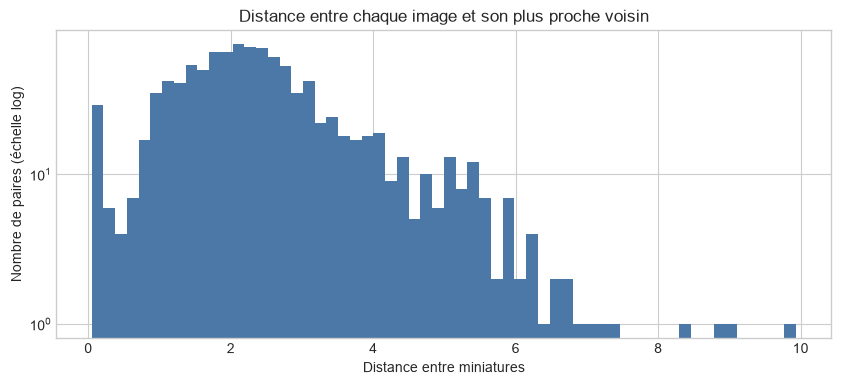

In [8]:
# Miniatures 32 × 32 comparées dans la seule orientation de l'image, avec la
# distance euclidienne.
SINGLE_ORIENTATION = NearDuplicateSearch(
    32, {"identity": ORIENTATIONS["identity"]}, rms=False
)
EUCLIDEAN_THRESHOLD = 0.15

all_pairs = find_near_duplicate_pairs(deduplicated, np.inf, SINGLE_ORIENTATION)

figure, axis = plt.subplots(figsize=(10, 4))
axis.hist(all_pairs["distance"], bins=60, color="#4C78A8")
axis.set_yscale("log")
axis.set(
    title="Distance entre chaque image et son plus proche voisin",
    xlabel="Distance entre miniatures",
    ylabel="Nombre de paires (échelle log)",
)
figure.savefig(
    FIGURES_DIR / "distances-voisins.png", dpi=120, bbox_inches="tight"
)
plt.show()

La distribution (chaque paire de plus proches voisins est comptée une fois) présente une queue de valeurs très faibles, nettement séparée du reste. On retient le seuil `EUCLIDEAN_THRESHOLD` = **0,15** et on inspecte visuellement les paires correspondantes.

In [9]:
subsets = deduplicated.set_index("image_id")["subset"]

pairs = all_pairs.query("distance < @EUCLIDEAN_THRESHOLD").assign(
    subset_a=lambda frame: frame["image_id_a"].map(subsets),
    subset_b=lambda frame: frame["image_id_b"].map(subsets),
)
pairs["implique_annotee"] = pairs["subset_a"].ne("sans_label") | pairs[
    "subset_b"
].ne("sans_label")
pairs = pairs.sort_values(
    ["implique_annotee", "distance"], ascending=[False, True]
).reset_index(drop=True)

print(
    f"{len(pairs)} paires de quasi-doublons (distance < {EUCLIDEAN_THRESHOLD})."
)
pair_types = [
    " + ".join(sorted(subsets_of_pair))
    for subsets_of_pair in zip(
        pairs["subset_a"], pairs["subset_b"], strict=True
    )
]
display(
    pd.Series(pair_types, name="sous-ensembles")
    .value_counts()
    .to_frame("paires")
)

24 paires de quasi-doublons (distance < 0.15).


,paires
sous-ensembles,
sans_label + sans_label,18
normal + sans_label,5
normal + normal,1


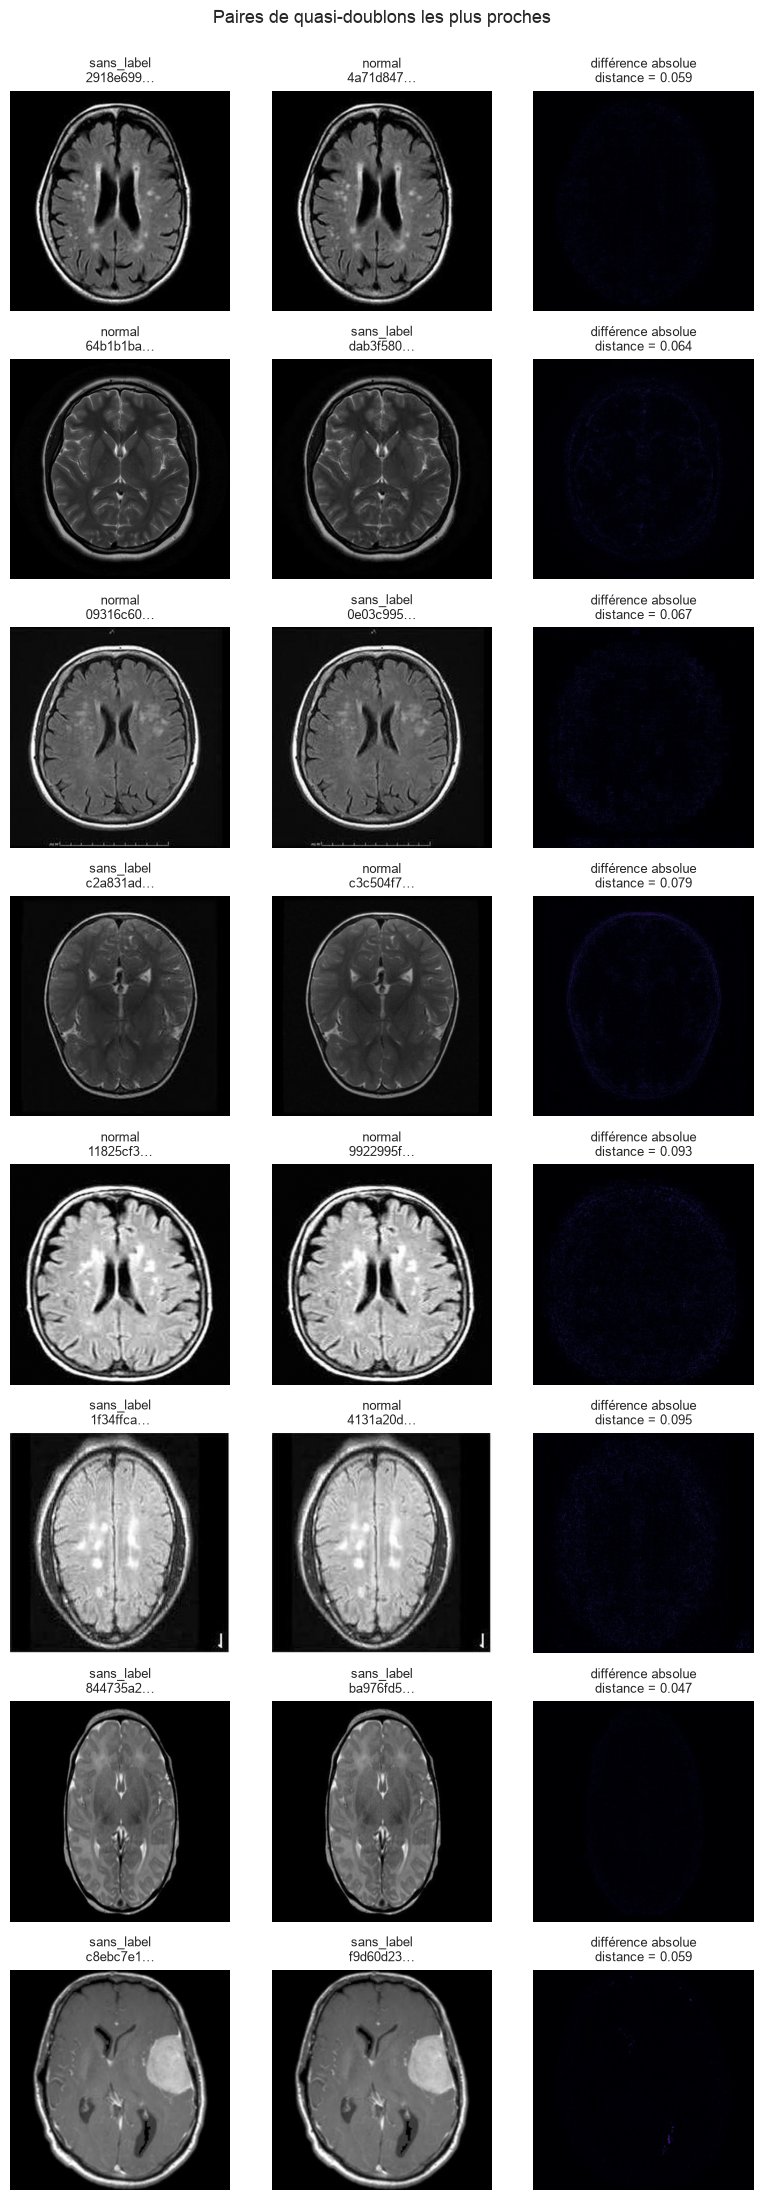

In [10]:
n_pairs_to_show = 8
shown = pairs.head(n_pairs_to_show)
by_id = deduplicated.set_index("image_id")

figure, axes = plt.subplots(
    len(shown), 3, figsize=(8, 2.8 * len(shown)), squeeze=False
)
for axis_row, (_, pair) in zip(axes, shown.iterrows(), strict=True):
    arrays = []
    for axis, side in zip(axis_row[:2], ("a", "b"), strict=True):
        image_id = pair[f"image_id_{side}"]
        row = by_id.loc[image_id]
        with Image.open(row["filepath"]) as image:
            array = np.asarray(image.convert("L"), dtype=np.float32)
        arrays.append(array)
        axis.imshow(array, cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"{row['subset']}\n{image_id[:8]}…", fontsize=9)

    axis_row[2].imshow(
        np.abs(arrays[0] - arrays[1]), cmap="magma", vmin=0, vmax=255
    )
    axis_row[2].set_title(
        f"différence absolue\ndistance = {pair['distance']:.3f}", fontsize=9
    )
    for axis in axis_row:
        axis.axis("off")

figure.suptitle("Paires de quasi-doublons les plus proches", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.98))
figure.savefig(
    FIGURES_DIR / "paires-quasi-doublons.png", dpi=120, bbox_inches="tight"
)
plt.show()

### Effet de la déduplication des quasi-doublons

Les paires inspectées sont visuellement identiques : la différence absolue est quasi nulle. On leur applique la même règle qu'aux doublons exacts : une copie annotée est conservée en priorité, puis l'`image_id` le plus petit. Cette étape est implémentée par `deduplicate_near`, et `deduplicate` enchaîne les deux.

In [11]:
near_deduplicated = deduplicate_near(
    deduplicated, EUCLIDEAN_THRESHOLD, SINGLE_ORIENTATION
)

# `deduplicate` applique aussi la liste d'exclusion manuelle : le manifeste
# obtenu à partir de l'inventaire complet doit être celui de ce notebook.
manifest, removed = deduplicate(
    inventory, EUCLIDEAN_THRESHOLD, search=SINGLE_ORIENTATION
)
pd.testing.assert_frame_equal(manifest, near_deduplicated)

summary_near = pd.concat(
    {
        "brut": inventory.groupby("subset").size(),
        "sans image exclue": images.groupby("subset").size(),
        "sans doublons exacts": deduplicated.groupby("subset").size(),
        "sans quasi-doublons": near_deduplicated.groupby("subset").size(),
    },
    axis=1,
)
summary_near.loc["total"] = summary_near.sum()
display(summary_near)

display(
    removed.groupby("reason").size().rename("images_retirées").reset_index()
)

,brut,sans image exclue,sans doublons exacts,sans quasi-doublons
subset,,,,
cancer,50,50,50,50
normal,50,50,49,48
sans_label,1406,1405,1310,1288
total,1506,1505,1409,1386


,reason,images_retirées
0,exact,96
1,excluded,1
2,near,23


## 7. Quasi-doublons retournés ou pivotés

La recherche précédente ne compare chaque image à ses voisines que **dans l'orientation d'origine** : une IRM retournée (miroir gauche-droite ou haut-bas) ou pivotée ne lui ressemble pas pixel à pixel et n'est jamais détectée. Or une copie retournée du même examen est aussi dangereuse qu'une copie identique : si l'une est en entraînement et l'autre en test, le test n'est plus « jamais vu ».

On compare donc chaque image aux **8 orientations** des autres (les symétries du carré : 4 rotations, avec ou sans miroir). Pour que le seuil ne dépende pas de la taille de la miniature, on mesure l'**écart quadratique moyen** (RMS) entre pixels dans [0, 1] : la distance euclidienne divisée par la racine du nombre de pixels. Les miniatures passent de 32 × 32 à **64 × 64** pour garder plus de détail.

In [12]:
IDENTITY_ONLY = NearDuplicateSearch(
    orientations={"identity": ORIENTATIONS["identity"]}
)

by_orientation = nearest_neighbors(deduplicated)
identity_only = nearest_neighbors(deduplicated, IDENTITY_ONLY)

by_orientation_pairs = find_near_duplicate_pairs(deduplicated, np.inf)
identity_pairs = find_near_duplicate_pairs(deduplicated, np.inf, IDENTITY_ONLY)

THRESHOLDS = (0.005, 0.01, 0.02, 0.03, 0.04)
comparison = pd.DataFrame(
    {
        "orientation d'origine seule": [
            int((identity_pairs["distance"] < threshold).sum())
            for threshold in THRESHOLDS
        ],
        "8 orientations": [
            int((by_orientation_pairs["distance"] < threshold).sum())
            for threshold in THRESHOLDS
        ],
        "dont retournées ou pivotées": [
            int(
                (
                    (by_orientation_pairs["distance"] < threshold)
                    & (by_orientation_pairs["transform"] != "identity")
                ).sum()
            )
            for threshold in THRESHOLDS
        ],
    },
    index=pd.Index(THRESHOLDS, name="RMS maximal"),
)
display(comparison)

,orientation d'origine seule,8 orientations,dont retournées ou pivotées
RMS maximal,,,
0.005,18,94,78
0.010,29,110,86
0.020,36,125,94
0.030,43,137,100
0.040,64,166,109


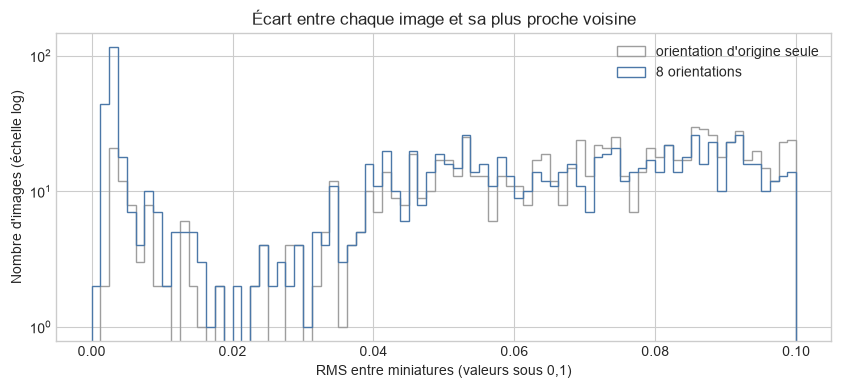

In [13]:
figure, axis = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 0.1, 81)
axis.hist(
    identity_only["distance"],
    bins=bins,
    histtype="step",
    color="#9E9E9E",
    label="orientation d'origine seule",
)
axis.hist(
    by_orientation["distance"],
    bins=bins,
    histtype="step",
    color="#4C78A8",
    label="8 orientations",
)
axis.set_yscale("log")
axis.set(
    title="Écart entre chaque image et sa plus proche voisine",
    xlabel="RMS entre miniatures (valeurs sous 0,1)",
    ylabel="Nombre d'images (échelle log)",
)
axis.legend()
figure.savefig(
    FIGURES_DIR / "distances-voisins-orientations.png",
    dpi=120,
    bbox_inches="tight",
)
plt.show()

### Où placer le seuil ? Revue visuelle

Les paires sont regroupées par bandes de distance. Pour chaque bande, six paires tirées au hasard montrent l'image A **remise dans l'orientation de l'image B**, l'image B et leur différence absolue : une copie donne une différence quasi noire. Le titre de chaque image indique sa netteté, mesurée en pleine résolution par la variance du laplacien.

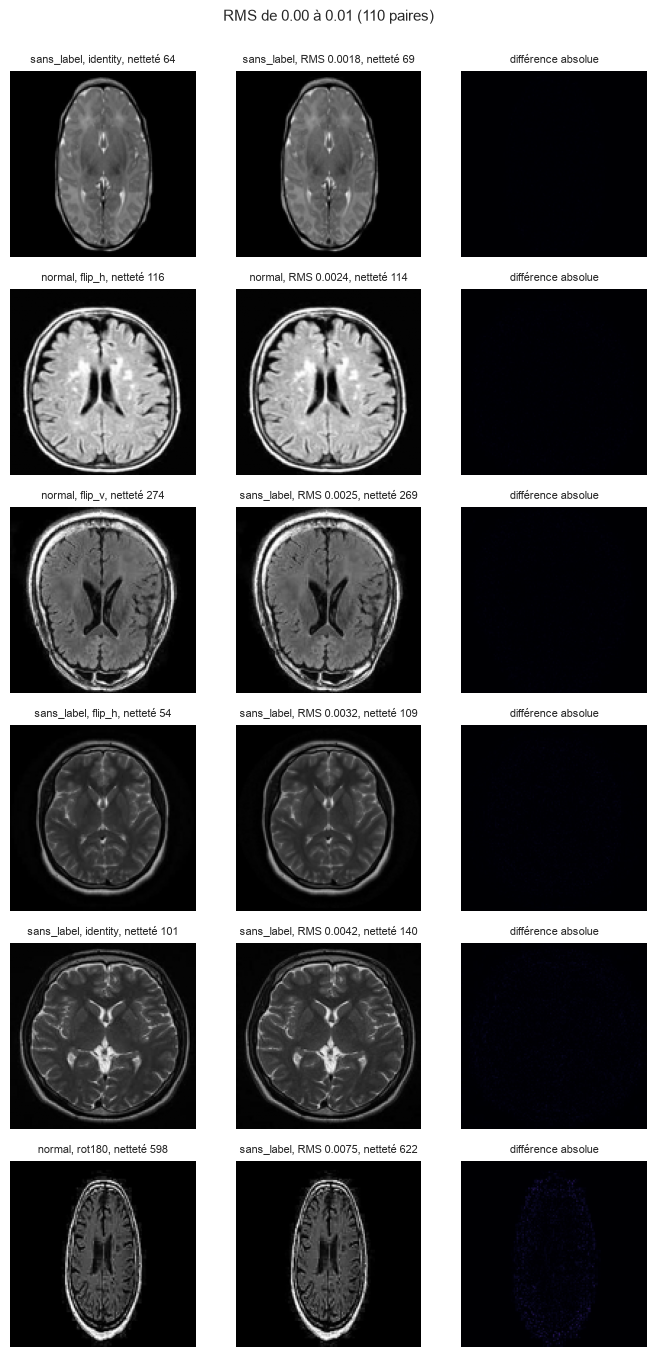

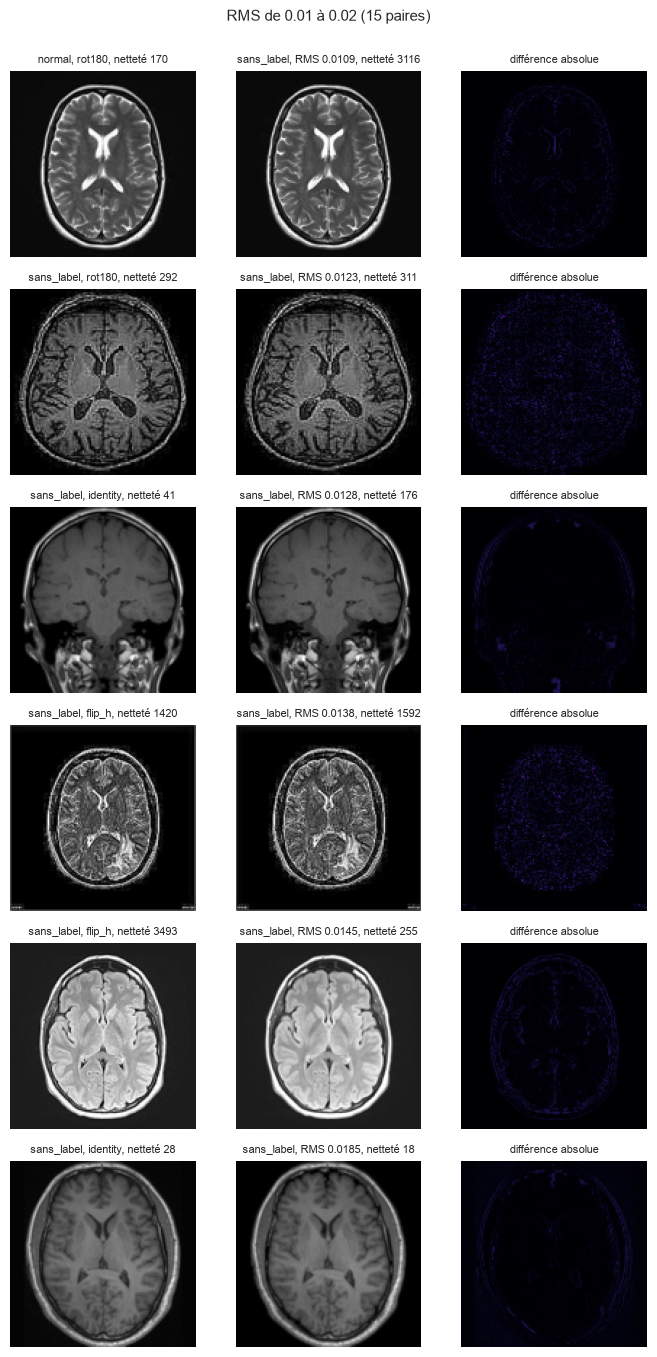

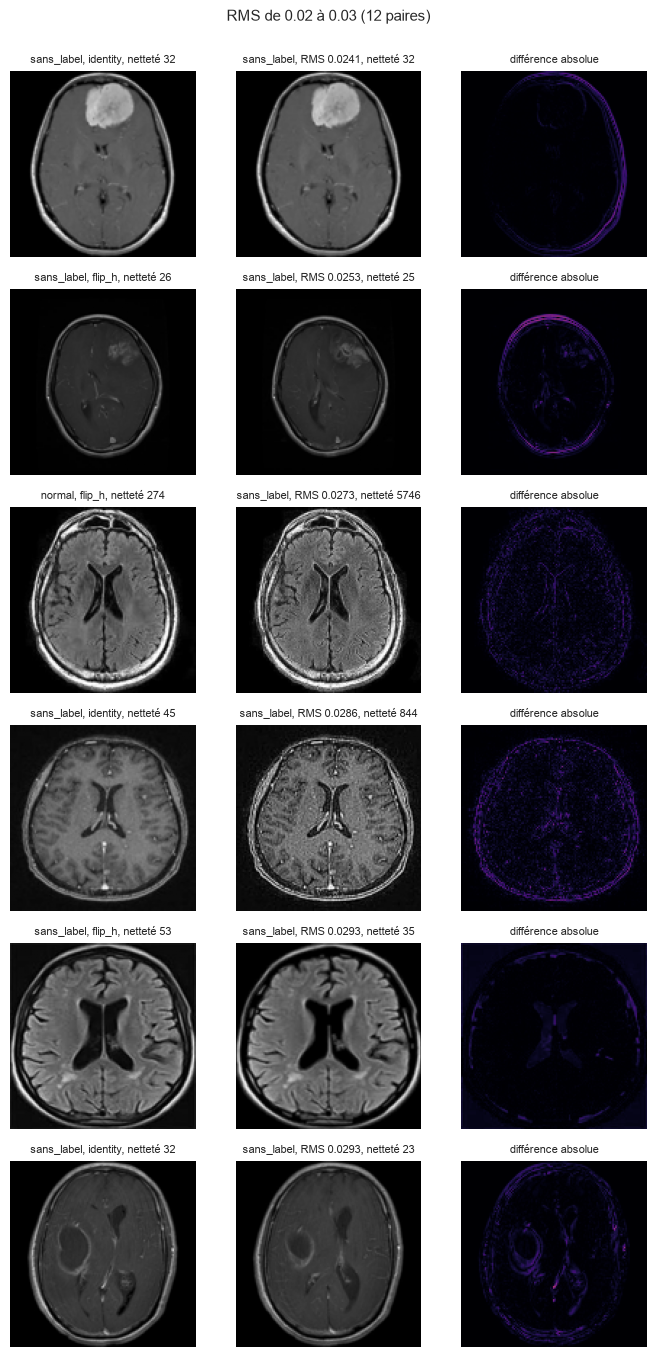

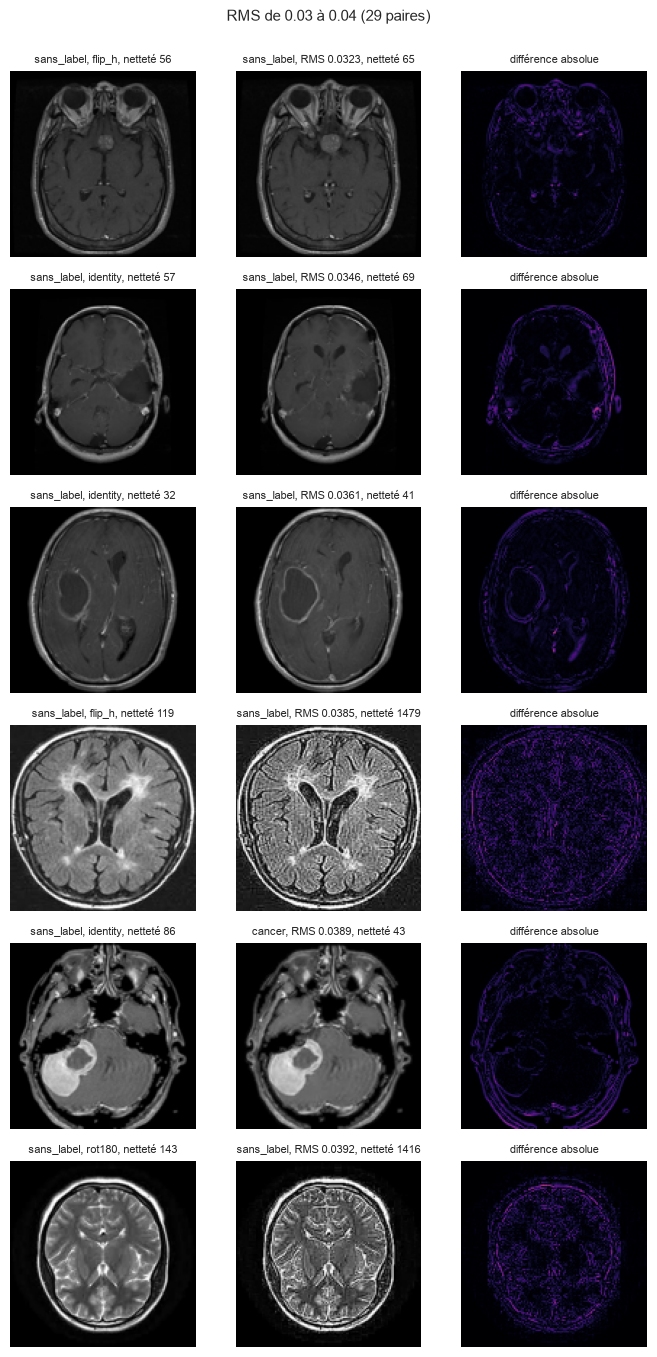

In [14]:
by_id = deduplicated.set_index("image_id")


def load_gray(image_id, side=128):
    """Charge une image en niveaux de gris, réduite à `side` pixels de côté."""
    with Image.open(by_id.at[image_id, "filepath"]) as image:
        resized = image.convert("L").resize((side, side))
    return np.asarray(resized, dtype=np.float32)


def sharpness(image_id):
    """Mesure la netteté : variance du laplacien, en pleine résolution.

    Plus la valeur est grande, plus les contours sont marqués.
    """
    with Image.open(by_id.at[image_id, "filepath"]) as image:
        gray = np.asarray(image.convert("L"))
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


def show_pairs(pairs, title, filename=None):
    """Affiche des paires : image A mise dans l'orientation de B, B, différence."""
    figure, axes = plt.subplots(
        len(pairs), 3, figsize=(7, 2.3 * len(pairs)), squeeze=False
    )
    for axis_row, (_, pair) in zip(axes, pairs.iterrows(), strict=True):
        first = ORIENTATIONS[pair["transform"]](load_gray(pair["image_id_a"]))
        second = load_gray(pair["image_id_b"])
        axis_row[0].imshow(first, cmap="gray", vmin=0, vmax=255)
        axis_row[0].set_title(
            f"{by_id.at[pair['image_id_a'], 'subset']}, {pair['transform']}, "
            f"netteté {sharpness(pair['image_id_a']):.0f}",
            fontsize=8,
        )
        axis_row[1].imshow(second, cmap="gray", vmin=0, vmax=255)
        axis_row[1].set_title(
            f"{by_id.at[pair['image_id_b'], 'subset']}, RMS {pair['distance']:.4f}, "
            f"netteté {sharpness(pair['image_id_b']):.0f}",
            fontsize=8,
        )
        axis_row[2].imshow(
            np.abs(first - second), cmap="magma", vmin=0, vmax=255
        )
        axis_row[2].set_title("différence absolue", fontsize=8)
        for axis in axis_row:
            axis.axis("off")
    figure.suptitle(title, fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.98))
    if filename:
        figure.savefig(FIGURES_DIR / filename, dpi=110, bbox_inches="tight")
    plt.show()


BANDS = ((0.0, 0.01), (0.01, 0.02), (0.02, 0.03), (0.03, 0.04))
for number, (low, high) in enumerate(BANDS, start=1):
    in_band = by_orientation_pairs[
        by_orientation_pairs["distance"].between(low, high, inclusive="left")
    ]
    sample = in_band.sample(min(6, len(in_band)), random_state=0).sort_values(
        "distance"
    )
    show_pairs(
        sample,
        f"RMS de {low:.2f} à {high:.2f} ({len(in_band)} paires)",
        f"quasi-doublons-bande-{number}.png",
    )

La **zone grise** entre 0,02 et 0,04 mérite un regard particulier pour les images annotées : retirer une copie annotée coûte une image d'évaluation.

41 paires de 0,02 à 0,04, dont 5 impliquent une image annotée.


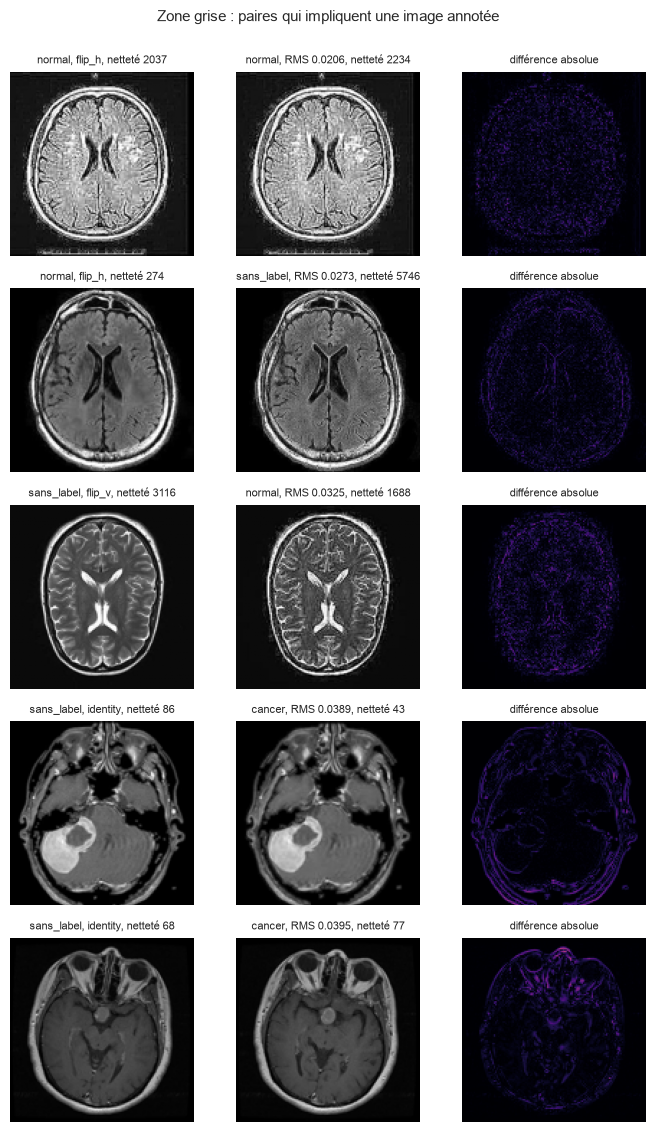

In [15]:
grey_zone = by_orientation_pairs[
    by_orientation_pairs["distance"].between(0.02, 0.04, inclusive="left")
]
involves_annotated = grey_zone["image_id_a"].map(
    by_id["is_labeled"]
) | grey_zone["image_id_b"].map(by_id["is_labeled"])
annotated_grey_zone = grey_zone[involves_annotated]
print(
    f"{len(grey_zone)} paires de 0,02 à 0,04, dont "
    f"{len(annotated_grey_zone)} impliquent une image annotée."
)
if len(annotated_grey_zone):
    show_pairs(
        annotated_grey_zone.head(6),
        "Zone grise : paires qui impliquent une image annotée",
        "quasi-doublons-zone-grise.png",
    )

### Seuil retenu

D'après les galeries :

- **sous 0,02**, les paires sont des **copies** : la différence ne montre que du bruit de compression, même lorsque l'image est retournée ou pivotée. Dans une partie des paires, une copie est **moins nette** que l'autre (variance du laplacien plus faible, à taille de fichier égale) ;
- **de 0,02 à 0,03**, on trouve encore des copies légèrement décalées ou à une autre échelle (les bords diffèrent), mêlées à des coupes voisines ;
- **au-delà de 0,03**, ce sont surtout des **coupes voisines d'un même examen** : elles se ressemblent, mais ce ne sont pas des copies.

On retient `NEAR_DUPLICATE_THRESHOLD` = **0,02** : on retire les copies sans retirer des images distinctes. Le seuil est conservateur pour les images annotées, dont chacune compte. Les coupes voisines d'un même examen restent un risque de fuite que l'on ne peut pas traiter sans métadonnées de patient : on le garde en tête comme **limite**.

In [16]:
near_pairs = by_orientation_pairs[
    by_orientation_pairs["distance"] < NEAR_DUPLICATE_THRESHOLD
].assign(
    subset_a=lambda frame: frame["image_id_a"].map(by_id["subset"]),
    subset_b=lambda frame: frame["image_id_b"].map(by_id["subset"]),
)
print(
    f"{len(near_pairs)} paires de quasi-doublons (RMS < {NEAR_DUPLICATE_THRESHOLD}), "
    f"contre {int((identity_pairs['distance'] < NEAR_DUPLICATE_THRESHOLD).sum())} "
    "avec l'orientation d'origine seule."
)
display(near_pairs["transform"].value_counts().to_frame("paires"))

pair_types = [
    " + ".join(sorted(subsets_of_pair))
    for subsets_of_pair in zip(
        near_pairs["subset_a"], near_pairs["subset_b"], strict=True
    )
]
display(
    pd.Series(pair_types, name="sous-ensembles")
    .value_counts()
    .to_frame("paires")
)

# Deux copies ne doivent jamais porter deux labels différents.
labels = by_id["label"]
conflicts = near_pairs[
    near_pairs["image_id_a"].map(labels).notna()
    & near_pairs["image_id_b"].map(labels).notna()
    & (
        near_pairs["image_id_a"].map(labels)
        != near_pairs["image_id_b"].map(labels)
    )
]
assert conflicts.empty, "Des quasi-doublons ont des labels contradictoires."
print("Aucune paire n'a de labels contradictoires.")

125 paires de quasi-doublons (RMS < 0.02), contre 36 avec l'orientation d'origine seule.


,paires
transform,
flip_h,63
identity,31
rot180,19
flip_v,12


,paires
sous-ensembles,
sans_label + sans_label,91
normal + sans_label,25
cancer + sans_label,6
normal + normal,3


Aucune paire n'a de labels contradictoires.


## 8. Résultat avec le seuil retenu

On applique la règle retenue (8 orientations, miniatures 64 × 64, seuil de 0,02) à l'inventaire complet avec `deduplicate`, qui exclut aussi l'image saturée et retire les doublons exacts. Le manifeste obtenu doit être celui que `make data` écrit sur le disque.

In [17]:
manifest, removed = deduplicate(inventory)

summary_final = pd.concat(
    {
        "brut": inventory.groupby("subset").size(),
        "sans image exclue": images.groupby("subset").size(),
        "sans doublons exacts": deduplicated.groupby("subset").size(),
        "sans quasi-doublons": manifest.groupby("subset").size(),
    },
    axis=1,
)
summary_final.loc["total"] = summary_final.sum()
display(summary_final)

display(
    removed.groupby("reason").size().rename("images_retirées").reset_index()
)
display(
    removed.loc[removed["reason"] == "near", "transform"]
    .value_counts()
    .to_frame("images_retirées")
)

on_disk = read_manifest(INTERIM_DATA_DIR / "manifest.csv")
if set(on_disk["image_id"]) != set(manifest["image_id"]):
    raise ValueError("Le manifeste du disque diffère : relancer `make data`.")
print("Le manifeste est identique à celui de `make data`.")

,brut,sans image exclue,sans doublons exacts,sans quasi-doublons
subset,,,,
cancer,50,50,50,50
normal,50,50,49,47
sans_label,1406,1405,1310,1194
total,1506,1505,1409,1291


,reason,images_retirées
0,exact,96
1,excluded,1
2,near,118


,images_retirées
transform,
flip_h,61
identity,27
rot180,18
flip_v,12


Le manifeste est identique à celui de `make data`.


## Conclusion de l'analyse

### Synthèse

- **Images illisibles** : aucune, les 1 506 fichiers se décodent. **Une image est exclue à la main** (tache blanche saturée, non annotée) : elle est retirée avant toute déduplication, il reste 1 505 images.
- **90 groupes de doublons exacts** (186 fichiers) : 96 copies sont en trop. Aucun groupe n'a de labels contradictoires. **31 groupes contiennent une image annotée**, dont 29 avec une copie non annotée : sans déduplication, ces copies pourraient fuiter entre apprentissage et évaluation. Une image `normal` est annotée **deux fois** : le jeu annoté passe de 50 à 49 images `normal`.
- **La comparaison dans la seule orientation de l'image laisse passer les copies retournées ou pivotées.** Avec les miniatures 32 × 32 (section 6), elle trouve 24 paires.
- **Avec les 8 orientations** (miniatures 64 × 64, écart quadratique moyen, RMS), on trouve **125 paires sous le seuil de 0,02**, contre 36 avec l'orientation d'origine seule : **94 sont retournées ou pivotées** (63 miroirs gauche-droite, 19 rotations de 180°, 12 miroirs haut-bas). Aucune paire n'a de labels contradictoires.
- **Les copies ne sont pas toujours de même netteté** : dans une partie des paires, une copie est moins nette que l'autre.
- **Résultat avec la règle retenue** : le manifeste compte **1 291 images** (1 506 brutes, moins 1 image exclue, 96 doublons exacts et 118 quasi-doublons), dont **97 annotées** (50 `cancer`, 47 `normal`) et 1 194 non annotées. Parmi les 118 quasi-doublons retirés, 91 sont des copies retournées ou pivotées (61 miroirs gauche-droite, 18 rotations de 180°, 12 miroirs haut-bas) et 27 des copies dans l'orientation d'origine. Le jeu annoté perd trois images `normal` (50 à 47).

### Décision

- **Exclusion manuelle** de l'image saturée, avant la déduplication (`EXCLUDED_IMAGES`).
- **Doublons exacts et quasi-doublons** : même règle, **une copie conservée par groupe**, en priorité une copie annotée, sinon l'`image_id` le plus petit.
- **Quasi-doublons** : comparaison dans les **8 orientations**, sur des miniatures **64 × 64**, seuil de **0,02** en RMS, choisi par revue visuelle des galeries. Sous 0,02, ce sont des copies ; au-delà de 0,03, ce sont surtout des coupes voisines d'un même examen, qu'on ne retire pas.
- **Zone grise** entre 0,02 et 0,04 : 41 paires, dont 5 impliquent une image annotée, à relire avant de figer le seuil.

Le manifeste dédupliqué, le rapport des suppressions et le découpage sont produits par `make data`, dans `data/interim/`, `data/processed/` et `reports/`.

### Limites

- Les **coupes voisines d'un même examen** ne sont pas des copies et ne sont pas retirées : sans métadonnées de patient, un risque de fuite subsiste entre apprentissage et évaluation.
- Le seuil de 0,02 est choisi par inspection visuelle, pas par un radiologue.
- Chaque image n'est comparée qu'à son plus proche voisin : une image qui aurait plusieurs copies est repérée par sa plus proche seulement.